In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
DATA_DIR = Path("/supplemental_clinical_data.csv")

clinical = pd.read_csv("/train_clinical_data.csv")
proteins = pd.read_csv("/train_proteins.csv")
peptides = pd.read_csv("/train_peptides.csv")
supplemental = pd.read_csv("/supplemental_clinical_data.csv")

print("All datasets loaded  successfully.")

All datasets loaded successfully.


In [ ]:
clinical['visit_id'].nunique()

2615

In [ ]:
protein_wide = proteins.pivot_table(
    index="visit_id",
    columns="UniProt",
    values="NPX",
    aggfunc="first"
)

print("Protein data in wide format:")
print("Rows (visits):", protein_wide.shape[0])
print("Columns (proteins):", protein_wide.shape[1])

protein_wide.head()


Protein data in wide format:
Rows (visits): 1113
Columns (proteins): 227


UniProt,O00391,O00533,O00584,O14498,O14773,O14791,O15240,O15394,O43505,O60888,...,Q9HDC9,Q9NQ79,Q9NYU2,Q9UBR2,Q9UBX5,Q9UHG2,Q9UKV8,Q9UNU6,Q9Y646,Q9Y6R7
visit_id,,,,,,,,,,,,,,,,,,,,,
10053_0,9104.27,402321.0,NaN,NaN,7150.57,2497.84,83002.9,15113.6,167327.0,129048.0,...,NaN,9469.45,94237.6,NaN,23016.0,177983.0,65900.0,15382.0,NaN,19017.40
10053_12,10464.20,435586.0,NaN,NaN,NaN,NaN,197117.0,15099.1,164268.0,108114.0,...,NaN,14408.40,NaN,NaN,28537.0,171733.0,65668.1,NaN,9295.65,25697.80
10053_18,13235.70,507386.0,7126.96,24525.7,NaN,2372.71,126506.0,16289.6,168107.0,163776.0,...,317477.0,38667.20,111107.0,NaN,37932.6,245188.0,59986.1,10813.3,NaN,29102.70
10138_12,12600.20,494581.0,9165.06,27193.5,22506.10,6015.90,156313.0,54546.4,204013.0,56725.0,...,557904.0,44556.90,155619.0,14647.9,36927.7,229232.0,106564.0,26077.7,21441.80,7642.42
10138_24,12003.20,522138.0,4498.51,17189.8,29112.40,2665.15,151169.0,52338.1,240892.0,85767.1,...,NaN,47836.70,177619.0,17061.1,25510.4,176722.0,59471.4,12639.2,15091.40,6168.55


In [ ]:
#Merging the two datasets (clinical data and the protein data)

merged_data = pd.merge(clinical, protein_wide, on='visit_id', how='inner')
display(merged_data.head())
print(merged_data.describe())

,visit_id,patient_id,visit_month,updrs_1,updrs_2,updrs_3,updrs_4,upd23b_clinical_state_on_medication,O00391,O00533,...,Q9HDC9,Q9NQ79,Q9NYU2,Q9UBR2,Q9UBX5,Q9UHG2,Q9UKV8,Q9UNU6,Q9Y646,Q9Y6R7
0,55_0,55,0,10.0,6.0,15.0,NaN,NaN,11254.3,732430.0,...,365475.0,35528.0,97005.6,23122.5,60912.6,408698.0,NaN,29758.8,23833.7,18953.5
1,55_6,55,6,8.0,10.0,34.0,NaN,NaN,13163.6,630465.0,...,405676.0,30332.6,109174.0,23499.8,51655.8,369870.0,NaN,22935.2,17722.5,16642.7
2,55_12,55,12,10.0,10.0,41.0,0.0,On,15257.6,815083.0,...,303953.0,43026.2,114921.0,21860.1,61598.2,318553.0,65762.6,29193.4,28536.1,19290.9
3,55_36,55,36,17.0,18.0,51.0,0.0,On,13530.8,753832.0,...,303597.0,48188.4,109794.0,23930.6,70223.5,377550.0,74976.1,31732.6,22186.5,21717.1
4,942_6,942,6,8.0,2.0,21.0,NaN,NaN,11218.7,399518.0,...,253373.0,27431.8,93796.7,17450.9,21299.1,306621.0,82335.5,24018.7,18939.5,15251.2


         patient_id  visit_month      updrs_1      updrs_2      updrs_3  \
count   1068.000000  1068.000000  1068.000000  1068.000000  1058.000000   
mean   32673.328652    26.744382     6.566479     5.821161    17.300567   
std    18612.372744    22.839426     5.330702     5.931414    15.016371   
min       55.000000     0.000000     0.000000     0.000000     0.000000   
25%    16574.000000     6.000000     2.000000     1.000000     2.000000   
50%    29365.000000    24.000000     5.000000     4.000000    16.000000   
75%    50611.000000    48.000000     9.000000     9.000000    28.000000   
max    65043.000000   108.000000    33.000000    29.000000    78.000000   

          updrs_4        O00391        O00533        O00584        O14498  \
count  569.000000    736.000000  1.067000e+03   1055.000000    989.000000   
mean     1.908612  11605.680568  5.092013e+05  26488.189128  27323.052376   
std      3.077419   2815.680292  2.336834e+05  10692.457986   8477.112143   
min      0.00000

In [ ]:
merged_data_sorted = merged_data.sort_values(by='patient_id', ascending=True)
display(merged_data_sorted.head())

,visit_id,patient_id,visit_month,updrs_1,updrs_2,updrs_3,updrs_4,upd23b_clinical_state_on_medication,O00391,O00533,...,Q9HDC9,Q9NQ79,Q9NYU2,Q9UBR2,Q9UBX5,Q9UHG2,Q9UKV8,Q9UNU6,Q9Y646,Q9Y6R7
0,55_0,55,0,10.0,6.0,15.0,NaN,NaN,11254.3,732430.0,...,365475.0,35528.0,97005.6,23122.5,60912.6,408698.0,NaN,29758.8,23833.7,18953.5
1,55_6,55,6,8.0,10.0,34.0,NaN,NaN,13163.6,630465.0,...,405676.0,30332.6,109174.0,23499.8,51655.8,369870.0,NaN,22935.2,17722.5,16642.7
2,55_12,55,12,10.0,10.0,41.0,0.0,On,15257.6,815083.0,...,303953.0,43026.2,114921.0,21860.1,61598.2,318553.0,65762.6,29193.4,28536.1,19290.9
3,55_36,55,36,17.0,18.0,51.0,0.0,On,13530.8,753832.0,...,303597.0,48188.4,109794.0,23930.6,70223.5,377550.0,74976.1,31732.6,22186.5,21717.1
4,942_6,942,6,8.0,2.0,21.0,NaN,NaN,11218.7,399518.0,...,253373.0,27431.8,93796.7,17450.9,21299.1,306621.0,82335.5,24018.7,18939.5,15251.2


In [ ]:
updrs_columns = ['updrs_1', 'updrs_2', 'updrs_3', 'updrs_4']
protein_columns = protein_wide.columns.tolist()

# Apply linear interpolation to UPDRS columns
for col in updrs_columns:
    if col in merged_data_sorted.columns:
        merged_data_sorted[col] = merged_data_sorted[col].interpolate(method='linear')

# Apply linear interpolation to protein columns
for col in protein_columns:
    if col in merged_data_sorted.columns:
        merged_data_sorted[col] = merged_data_sorted[col].interpolate(method='linear')

# Display the head of the DataFrame after interpolation
display(merged_data_sorted.head())

,visit_id,patient_id,visit_month,updrs_1,updrs_2,updrs_3,updrs_4,upd23b_clinical_state_on_medication,O00391,O00533,...,Q9HDC9,Q9NQ79,Q9NYU2,Q9UBR2,Q9UBX5,Q9UHG2,Q9UKV8,Q9UNU6,Q9Y646,Q9Y6R7
0,55_0,55,0,10.0,6.0,15.0,NaN,NaN,11254.3,732430.0,...,365475.0,35528.0,97005.6,23122.5,60912.6,408698.0,NaN,29758.8,23833.7,18953.5
1,55_6,55,6,8.0,10.0,34.0,NaN,NaN,13163.6,630465.0,...,405676.0,30332.6,109174.0,23499.8,51655.8,369870.0,NaN,22935.2,17722.5,16642.7
2,55_12,55,12,10.0,10.0,41.0,0.0,On,15257.6,815083.0,...,303953.0,43026.2,114921.0,21860.1,61598.2,318553.0,65762.6,29193.4,28536.1,19290.9
3,55_36,55,36,17.0,18.0,51.0,0.0,On,13530.8,753832.0,...,303597.0,48188.4,109794.0,23930.6,70223.5,377550.0,74976.1,31732.6,22186.5,21717.1
4,942_6,942,6,8.0,2.0,21.0,0.0,NaN,11218.7,399518.0,...,253373.0,27431.8,93796.7,17450.9,21299.1,306621.0,82335.5,24018.7,18939.5,15251.2



Performing Lasso regression for target: updrs_1


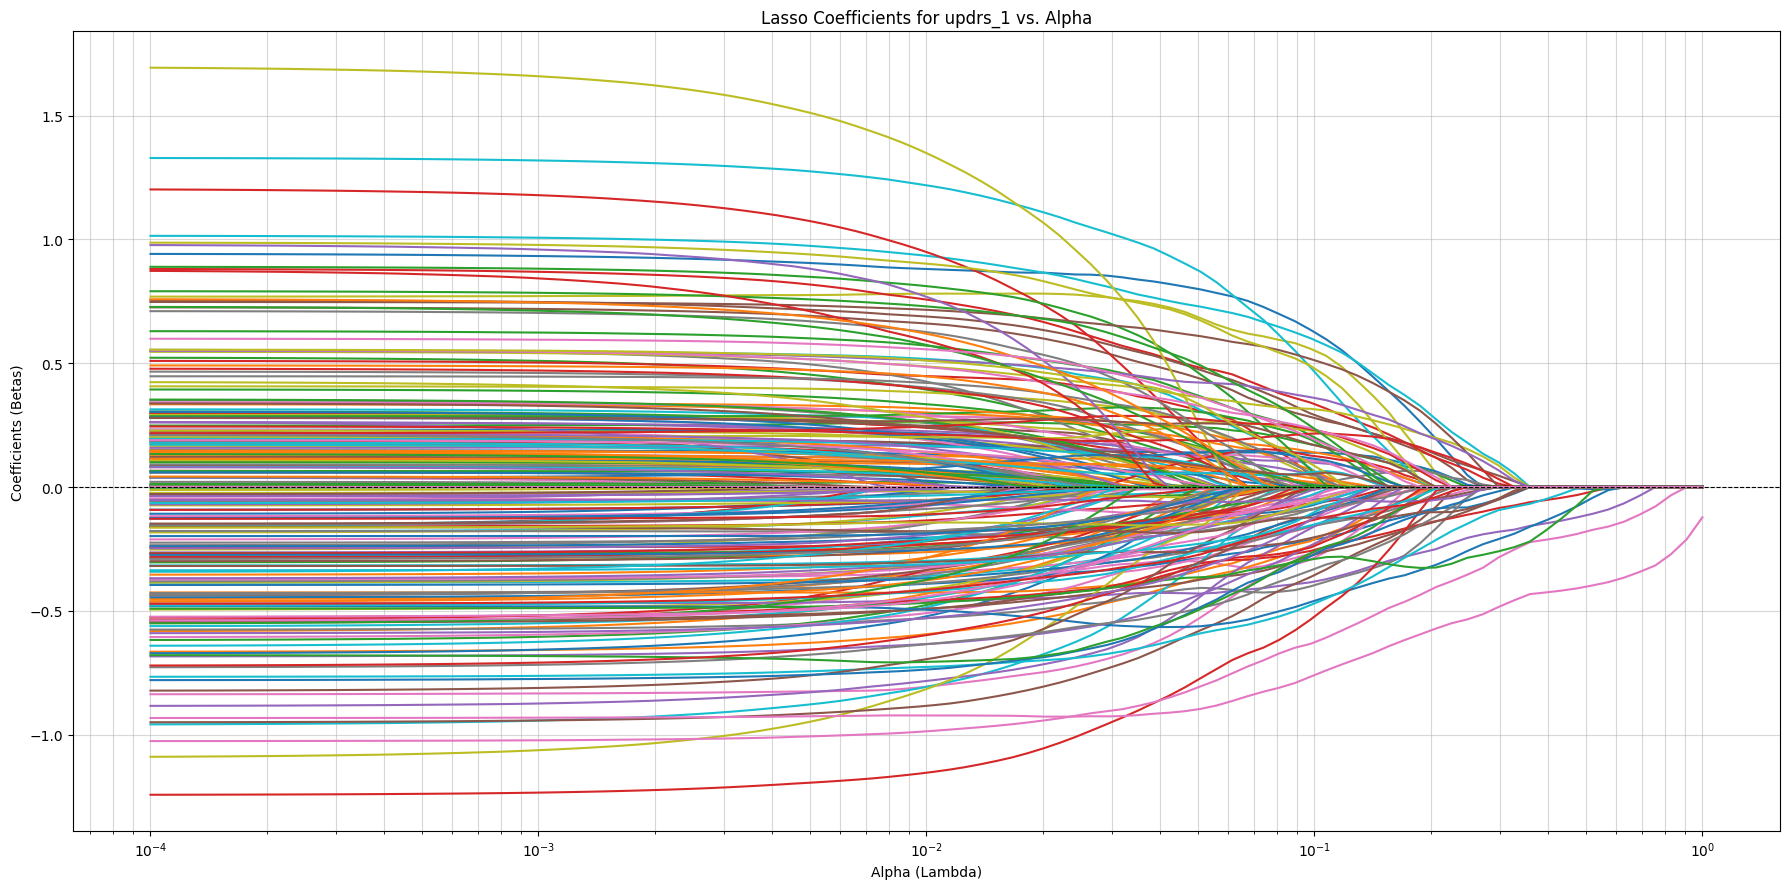


Performing Lasso regression for target: updrs_2


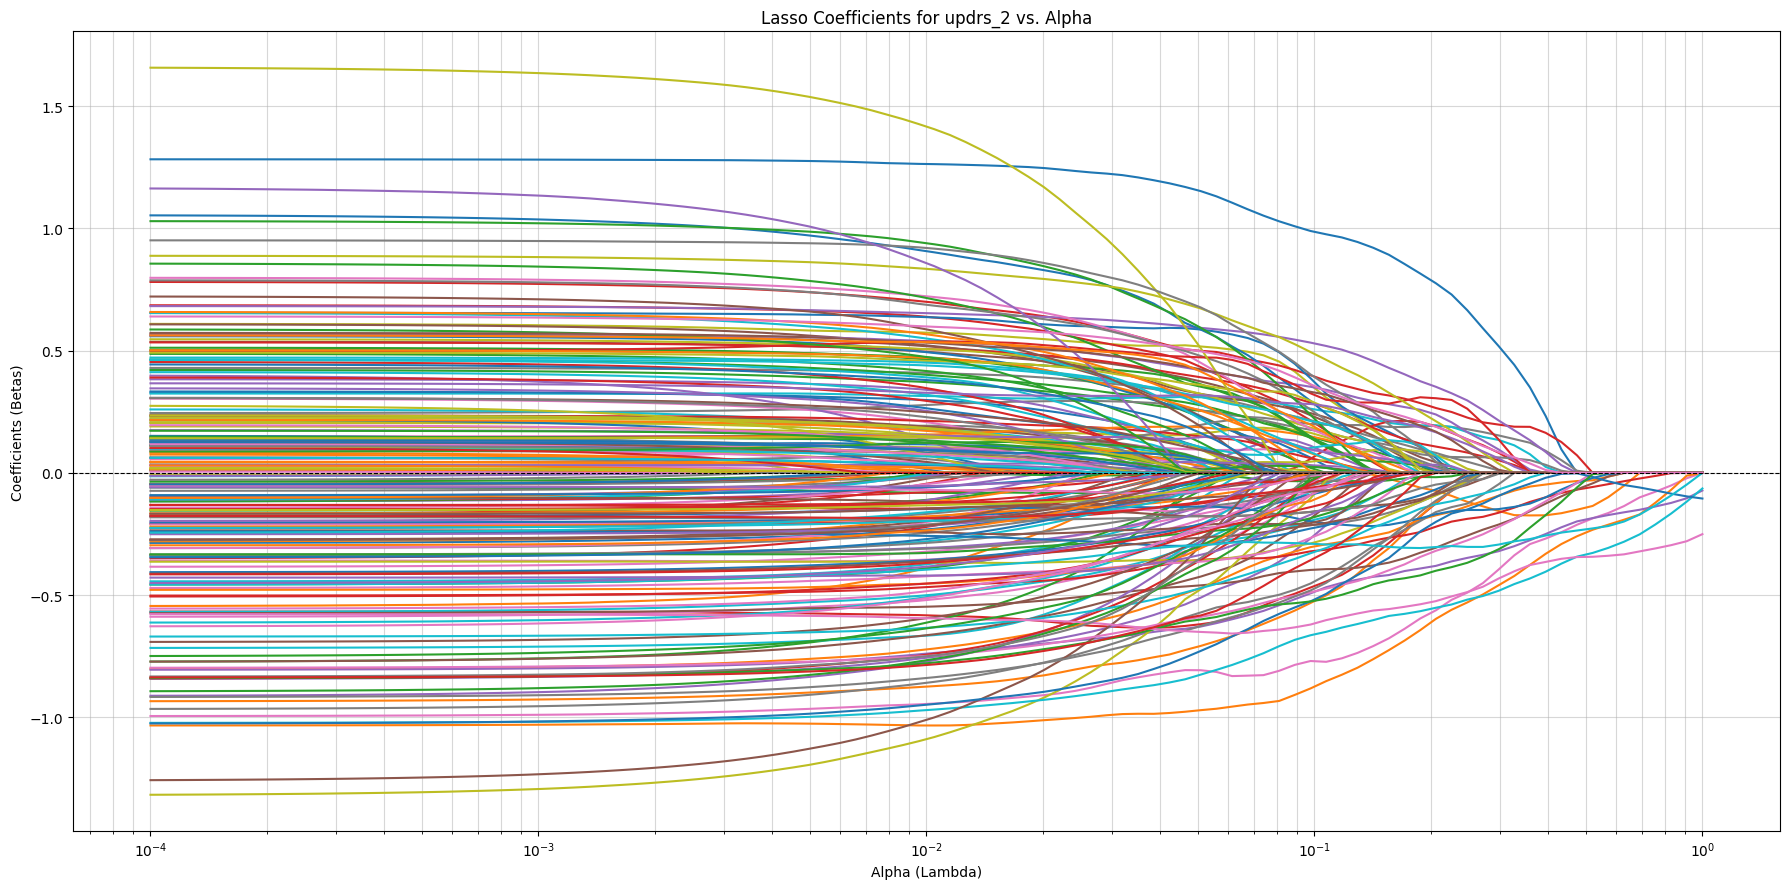


Performing Lasso regression for target: updrs_3


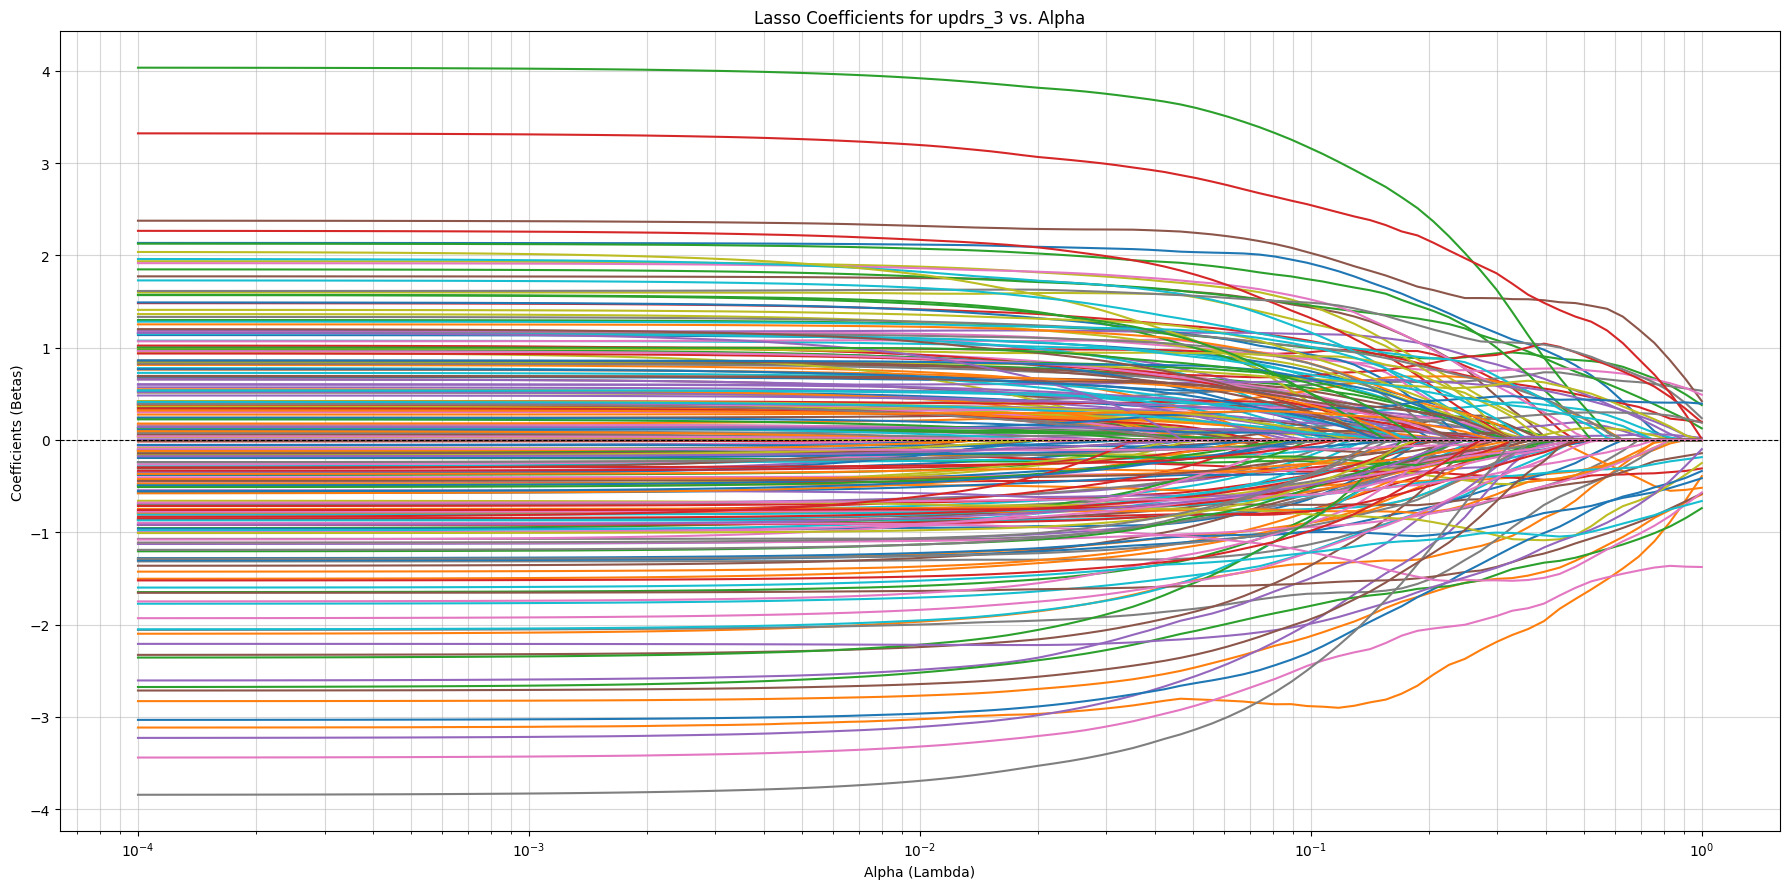


Performing Lasso regression for target: updrs_4


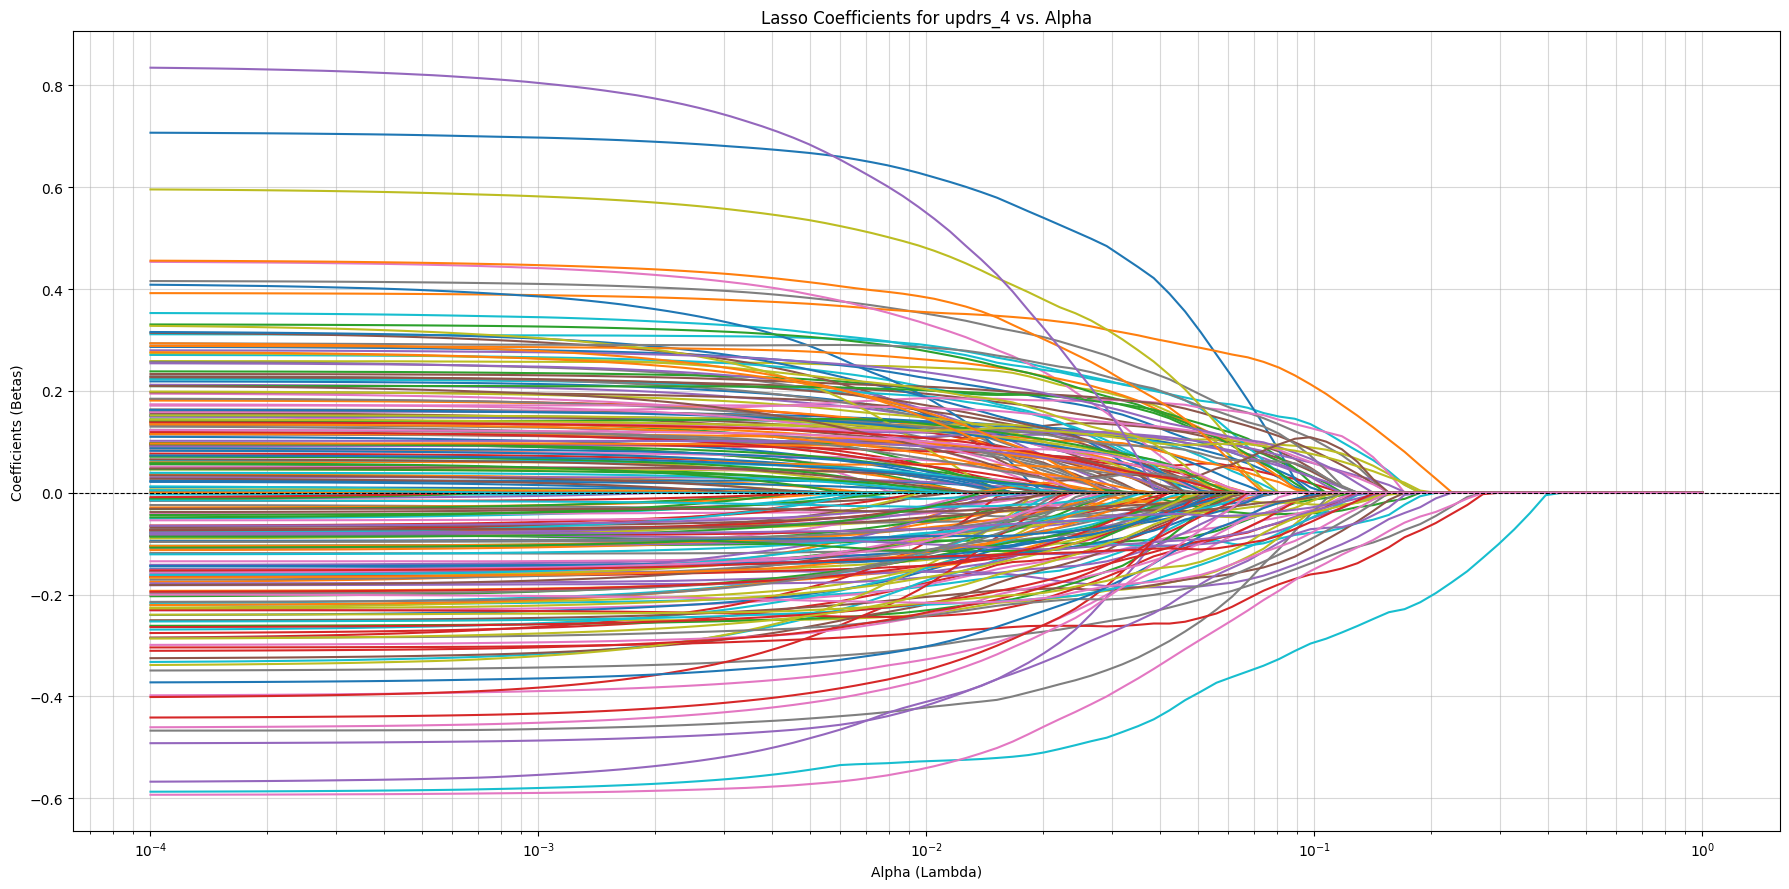

In [ ]:
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler

# Define alpha values for Lasso (lambda)
alphas = np.logspace(-4, 0, 100) # 100 values from 0.0001 to 1

# Prepare features (protein scores) from the merged and interpolated data
X_proteins = merged_data_sorted[protein_columns]

# Initialize StandardScaler
scaler = StandardScaler()

# Iterate through each UPDRS score to perform Lasso regression
for updrs_col in updrs_columns:
    print(f"\nPerforming Lasso regression for target: {updrs_col}")

    # Prepare the target variable
    y_updrs = merged_data_sorted[updrs_col]

    # Combine X and y to drop NaNs consistently for the current target
    # This ensures that only rows with complete data for both proteins and the current UPDRS score are used
    temp_df = pd.concat([X_proteins, y_updrs], axis=1).dropna()

    if temp_df.empty:
        print(f"  Skipping {updrs_col}: No complete cases after dropping NaNs.")
        continue

    X_clean = temp_df[protein_columns]
    y_clean = temp_df[updrs_col]

    # Scale the protein features
    X_scaled = scaler.fit_transform(X_clean)

    # Store coefficients for each alpha value
    coefs = []
    for a in alphas:
        # Initialize Lasso model with current alpha and increased max_iter for convergence
        lasso = Lasso(alpha=a, max_iter=50000, random_state=42)
        lasso.fit(X_scaled, y_clean)
        coefs.append(lasso.coef_)

    # Plot coefficients for the current UPDRS score
    fig, ax = plt.subplots(figsize=(18, 9)) # Increased figure size
    ax.plot(alphas, coefs)
    ax.set_xscale('log')
    plt.xlabel('Alpha (Lambda)')
    plt.ylabel('Coefficients (Betas)')
    plt.title(f'Lasso Coefficients for {updrs_col} vs. Alpha')
    # Place legend outside the plot area for better readability
    #ax.legend(protein_columns, bbox_to_anchor=(1.05, 1), loc='upper left', fontsize='small')
    plt.axhline(0, color='black', linestyle='--', linewidth=0.8) # Add a horizontal line at 0
    plt.grid(True, which="both", ls="-", alpha=0.5)
    plt.tight_layout() # Adjust layout to prevent labels/legend from being cut off
    plt.show()


Performing K-fold cross-validation for target: updrs_1


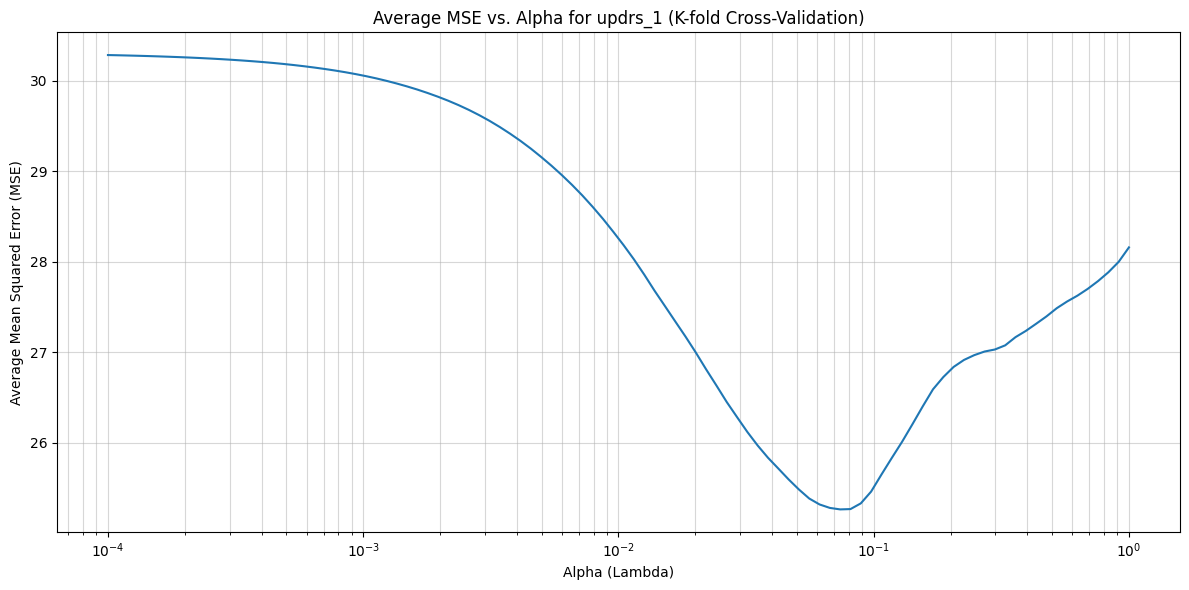


Performing K-fold cross-validation for target: updrs_2


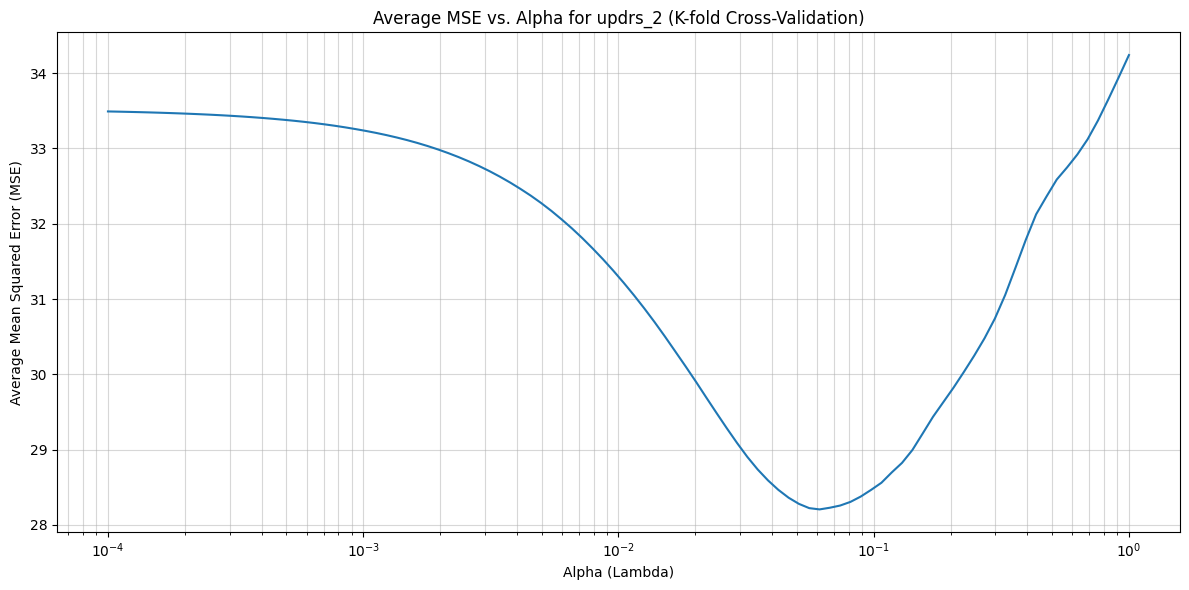


Performing K-fold cross-validation for target: updrs_3


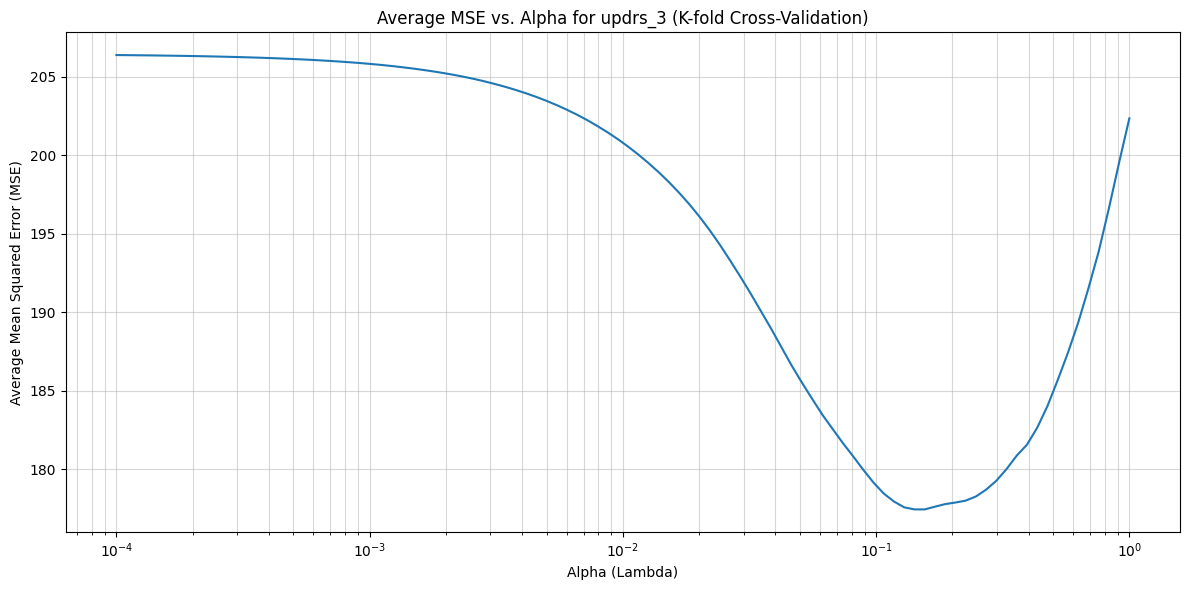


Performing K-fold cross-validation for target: updrs_4


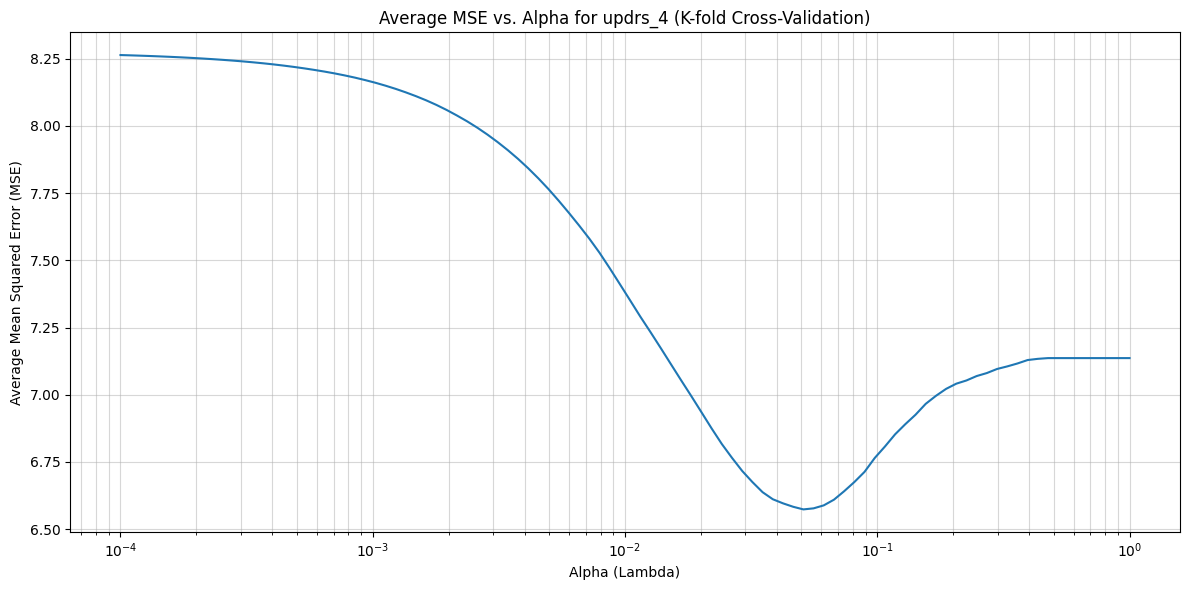

In [ ]:
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error

# Define the number of folds for cross-validation
n_splits = 5
kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

# Store MSEs for plotting later
all_mses = {}

# Iterate through each UPDRS score
for updrs_col in updrs_columns:
    print(f"\nPerforming K-fold cross-validation for target: {updrs_col}")

    # Prepare the target variable
    y_updrs = merged_data_sorted[updrs_col]

    # Combine X and y to drop NaNs consistently for the current target
    temp_df = pd.concat([X_proteins, y_updrs], axis=1).dropna()

    if temp_df.empty:
        print(f"  Skipping {updrs_col}: No complete cases after dropping NaNs.")
        continue

    X_clean = temp_df[protein_columns]
    y_clean = temp_df[updrs_col]

    # Dictionary to store MSEs for each alpha across folds
    mse_for_alphas = {a: [] for a in alphas}

    # Perform K-fold cross-validation
    for fold, (train_index, test_index) in enumerate(kf.split(X_clean)):
        # Split data into training and testing sets for the current fold
        X_train, X_test = X_clean.iloc[train_index], X_clean.iloc[test_index]
        y_train, y_test = y_clean.iloc[train_index], y_clean.iloc[test_index]

        # Initialize and fit StandardScaler on the training data
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

        # Iterate through each alpha value
        for a in alphas:
            # Initialize and fit Lasso model
            lasso = Lasso(alpha=a, max_iter=50000, random_state=42)
            lasso.fit(X_train_scaled, y_train)

            # Make predictions on the scaled test set
            y_pred = lasso.predict(X_test_scaled)

            # Calculate Mean Squared Error
            mse = mean_squared_error(y_test, y_pred)
            mse_for_alphas[a].append(mse)

    # Calculate the average MSE for each alpha across all folds
    avg_mses = {a: np.mean(mses) for a, mses in mse_for_alphas.items()}
    all_mses[updrs_col] = avg_mses

    # Plot MSE vs. Alpha
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.plot(list(avg_mses.keys()), list(avg_mses.values()))
    ax.set_xscale('log')
    plt.xlabel('Alpha (Lambda)')
    plt.ylabel('Average Mean Squared Error (MSE)')
    plt.title(f'Average MSE vs. Alpha for {updrs_col} (K-fold Cross-Validation)')
    plt.grid(True, which="both", ls="-", alpha=0.5)
    plt.tight_layout()
    plt.show()

In [ ]:
optimal_alphas = {}
for updrs_col, mses in all_mses.items():
    # Find the alpha with the minimum MSE
    min_mse_alpha = min(mses, key=mses.get)
    optimal_alphas[updrs_col] = min_mse_alpha

print("Optimal Alpha (Lambda) for each UPDRS score:")
for updrs_col, alpha in optimal_alphas.items():
    print(f"  {updrs_col}: {alpha:.6f}")

Optimal Alpha (Lambda) for each UPDRS score:
  updrs_1: 0.073907
  updrs_2: 0.061359
  updrs_3: 0.155568
  updrs_4: 0.050941


In [ ]:
print("Minimum MSE for each UPDRS score:")
for updrs_col, mses in all_mses.items():
    min_mse_value = min(mses.values())
    print(f"  {updrs_col}: {min_mse_value:.6f}")


Minimum MSE for each UPDRS score:
  updrs_1: 25.265457
  updrs_2: 28.206042
  updrs_3: 177.436652
  updrs_4: 6.573358


In [ ]:
protein_stickiness = {}

for updrs_col in updrs_columns:
    print(f"\nAnalyzing protein stickiness for {updrs_col}")

    y_updrs = merged_data_sorted[updrs_col]
    temp_df = pd.concat([X_proteins, y_updrs], axis=1).dropna()

    if temp_df.empty:
        print(f"  Skipping {updrs_col}: No complete cases after dropping NaNs.")
        continue

    X_clean = temp_df[protein_columns]
    y_clean = temp_df[updrs_col]

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_clean)

    # Dictionary to store the highest alpha at which a protein's coefficient is non-zero
    # Initialize with 0 (or a very small number) for all proteins
    last_non_zero_alpha = {prot: 0 for prot in protein_columns}

    # Sort alphas to iterate from smallest to largest to track when coefficients become non-zero
    # However, to find the 'highest alpha for which coefficient is non-zero', it's better to iterate in reverse.
    # No, to find the 'most sticky' (survive highest alpha), we iterate smallest to largest.
    # If a coef is non-zero at alpha 'a', it means it 'survived' up to 'a'.
    # The last recorded 'a' for which it is non-zero is its max survival alpha.

    # Let's iterate from largest alpha to smallest. The *first* alpha where a coefficient is non-zero
    # when moving from large to small alpha, tells us the 'highest alpha it survived'.
    # This is equivalent to finding the last non-zero alpha when iterating small to large.

    for a in sorted(alphas, reverse=True): # Iterate from large alpha (more coefficients are zero) to small
        lasso = Lasso(alpha=a, max_iter=50000, random_state=42)
        lasso.fit(X_scaled, y_clean)

        for i, prot in enumerate(protein_columns):
            if abs(lasso.coef_[i]) > 1e-9: # Check if coefficient is effectively non-zero
                # If we haven't recorded this protein yet, or if current 'a' is higher than recorded
                if last_non_zero_alpha[prot] == 0 or a > last_non_zero_alpha[prot]:
                    last_non_zero_alpha[prot] = a

    # Sort proteins by their last non-zero alpha in descending order (most sticky first)
    sorted_proteins_by_stickiness = sorted(
        last_non_zero_alpha.items(), key=lambda item: item[1], reverse=True
    )
    protein_stickiness[updrs_col] = sorted_proteins_by_stickiness


Analyzing protein stickiness for updrs_1

Analyzing protein stickiness for updrs_2

Analyzing protein stickiness for updrs_3

Analyzing protein stickiness for updrs_4


### Protein Stickiness and Optimal Alpha for Each UPDRS Score

Below are tables for each UPDRS score showing the proteins ordered by their 'stickiness' (i.e., the highest alpha value at which their coefficient remained non-zero). The table for each score is cut off at its respective optimal alpha, meaning only proteins whose coefficients are still non-zero at or above the optimal alpha are listed.

In [ ]:
for updrs_col in updrs_columns:
    optimal_alpha = optimal_alphas.get(updrs_col)
    if optimal_alpha is None: # Skip if no optimal alpha was found (e.g., due to empty data)
        continue

    print(f"\n#### {updrs_col} (Optimal Alpha: {optimal_alpha:.6f})\n")
    print("| Rank | Protein | Highest Alpha (non-zero coeff) |")
    print("|------|---------|--------------------------------|")

    rank = 1
    for protein, max_alpha in protein_stickiness.get(updrs_col, []):
        if max_alpha >= optimal_alpha:
            print(f"| {rank}    | {protein} | {max_alpha:.6f}                         |")
            rank += 1
        else:
            # Once we hit a protein that is 'killed' before or at the optimal alpha, we stop.
            # This assumes that the list `sorted_proteins_by_stickiness` is sorted by `max_alpha` in descending order.
            break


#### updrs_1 (Optimal Alpha: 0.073907)

| Rank | Protein | Highest Alpha (non-zero coeff) |
|------|---------|--------------------------------|
| 1    | Q06481 | 1.000000                         |
| 2    | P17174 | 0.830218                         |
| 3    | P04180 | 0.689261                         |
| 4    | P43121 | 0.628029                         |
| 5    | P05060 | 0.572237                         |
| 6    | P14314 | 0.572237                         |
| 7    | P43652 | 0.521401                         |
| 8    | P19021 | 0.475081                         |
| 9    | P01834 | 0.359381                         |
| 10    | P01033 | 0.327455                         |
| 11    | P02766 | 0.327455                         |
| 12    | P08133 | 0.327455                         |
| 13    | P60174 | 0.327455                         |
| 14    | Q6UX71 | 0.327455                         |
| 15    | Q6UXB8 | 0.327455                         |
| 16    | P01009 | 0.298365                         |


In [ ]:
optimal_coefs_per_updrs = {}

print("\n--- Coefficients at Optimal Alpha ---")

for updrs_col in updrs_columns:
    optimal_alpha = optimal_alphas.get(updrs_col)
    if optimal_alpha is None:
        continue

    print(f"\n#### {updrs_col} (Optimal Alpha: {optimal_alpha:.6f})\n")

    # Prepare clean data for the current UPDRS score
    y_updrs = merged_data_sorted[updrs_col]
    temp_df = pd.concat([X_proteins, y_updrs], axis=1).dropna()

    if temp_df.empty:
        print(f"  Skipping {updrs_col}: No complete cases after dropping NaNs.")
        continue

    X_clean = temp_df[protein_columns]
    y_clean = temp_df[updrs_col]

    # Scale features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_clean)

    # Fit Lasso model with the optimal alpha
    lasso = Lasso(alpha=optimal_alpha, max_iter=50000, random_state=42)
    lasso.fit(X_scaled, y_clean)

    # Store non-zero coefficients
    current_updrs_coefs = {}
    for i, prot in enumerate(protein_columns):
        if abs(lasso.coef_[i]) > 1e-9:  # Check for effectively non-zero coefficients
            current_updrs_coefs[prot] = lasso.coef_[i]

    optimal_coefs_per_updrs[updrs_col] = current_updrs_coefs

    # Sort coefficients by absolute value for display
    sorted_coefs = sorted(current_updrs_coefs.items(), key=lambda item: abs(item[1]), reverse=True)

    if not sorted_coefs:
        print("  No proteins retained at this optimal alpha.")
    else:
        print("| Rank | Protein | Coefficient |")
        print("|------|---------|-------------|")
        for rank, (protein, coef) in enumerate(sorted_coefs, 1):
            print(f"| {rank:<4} | {protein:<7} | {coef:11.6f} |")


--- Coefficients at Optimal Alpha ---

#### updrs_1 (Optimal Alpha: 0.073907)

| Rank | Protein | Coefficient |
|------|---------|-------------|
| 1    | Q06481  |   -0.826682 |
| 2    | O75144  |    0.727354 |
| 3    | P17174  |   -0.700015 |
| 4    | P10909  |    0.675092 |
| 5    | P01033  |    0.666751 |
| 6    | P16070  |   -0.648695 |
| 7    | O43505  |    0.608640 |
| 8    | Q14515  |    0.567343 |
| 9    | Q13740  |    0.567343 |
| 10   | P19021  |   -0.539885 |
| 11   | P14314  |   -0.518483 |
| 12   | P13591  |   -0.450232 |
| 13   | P02774  |   -0.426064 |
| 14   | P04180  |   -0.408415 |
| 15   | P39060  |   -0.405706 |
| 16   | P01009  |    0.404893 |
| 17   | Q6UX71  |    0.396518 |
| 18   | P02766  |    0.383446 |
| 19   | P61916  |   -0.369578 |
| 20   | P43121  |   -0.364256 |
| 21   | P02768  |   -0.363891 |
| 22   | Q8NE71  |    0.361371 |
| 23   | O14791  |    0.338341 |
| 24   | P08133  |   -0.338137 |
| 25   | P60174  |    0.328558 |
| 26   | P43652  |   -0.32736

### Proteins Surviving in All UPDRS Regression Models

Below is a list of proteins that maintained a non-zero coefficient at the optimal alpha across *all four* UPDRS scores. Their average coefficient value across these models is also provided.

In [ ]:
# Find proteins that survive in all UPDRS models
surviving_proteins_sets = {}
for updrs_col, coefs_dict in optimal_coefs_per_updrs.items():
    surviving_proteins_sets[updrs_col] = set(coefs_dict.keys())

# Get the intersection of all sets
if surviving_proteins_sets:
    universally_surviving_proteins = set.intersection(*surviving_proteins_sets.values())
else:
    universally_surviving_proteins = set()

# Calculate average coefficients for universally surviving proteins
average_universal_coefs = {}
if universally_surviving_proteins:
    for protein in universally_surviving_proteins:
        coef_values = []
        for updrs_col in updrs_columns:
            if protein in optimal_coefs_per_updrs[updrs_col]:
                coef_values.append(optimal_coefs_per_updrs[updrs_col][protein])
        if coef_values: # Ensure we have values to average
            a = np.mean(coef_values)
            average_universal_coefs[protein] = a

# Sort by absolute average coefficient for display
sorted_average_universal_coefs = sorted(
    average_universal_coefs.items(), key=lambda item: abs(item[1]), reverse=True
)

print("| Rank | Protein | Average Coefficient (across UPDRS scores) |")
print("|------|---------|-----------------------------------------|")
if not sorted_average_universal_coefs:
    print("No proteins found that survive in all 4 UPDRS models.")
else:
    for rank, (protein, avg_coef) in enumerate(sorted_average_universal_coefs, 1):
        print(f"| {rank:<4} | {protein:<7} | {avg_coef:39.6f} |")

| Rank | Protein | Average Coefficient (across UPDRS scores) |
|------|---------|-----------------------------------------|
| 1    | O75144  |                                0.894757 |
| 2    | Q06481  |                               -0.793402 |
| 3    | P02774  |                               -0.651606 |
| 4    | P43652  |                               -0.644123 |
| 5    | P19021  |                               -0.496275 |
| 6    | P39060  |                               -0.480338 |
| 7    | P01009  |                                0.463662 |
| 8    | P01861  |                                0.440594 |
| 9    | P08133  |                               -0.413515 |
| 10   | P60174  |                                0.398533 |
| 11   | P17174  |                               -0.398396 |
| 12   | P01859  |                                0.394473 |
| 13   | P04180  |                               -0.374940 |
| 14   | P01033  |                                0.368931 |
| 15   | Q9UKV8  |    

/tmp/ipykernel_488/2826374701.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Protein', y='Stickiness (Highest Alpha)', data=stickiness_df, palette='viridis')


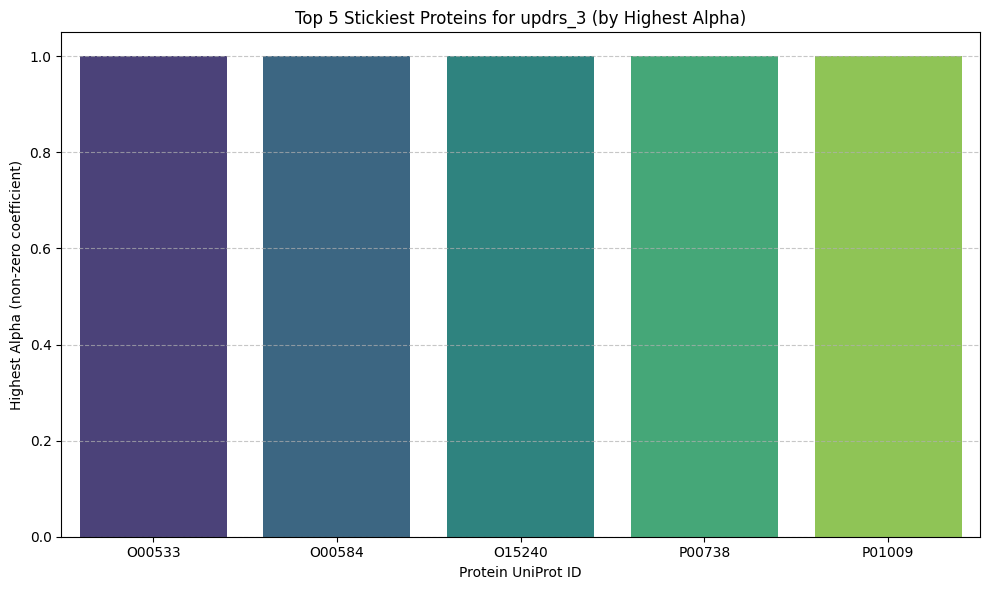

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get the top 5 stickiest proteins for updrs_3
top_5_updrs3_stickiness = protein_stickiness['updrs_3'][:5]

# Extract protein names and stickiness values
proteins = [item[0] for item in top_5_updrs3_stickiness]
stickiness_values = [item[1] for item in top_5_updrs3_stickiness]

# Create a DataFrame for easy plotting
stickiness_df = pd.DataFrame({
    'Protein': proteins,
    'Stickiness (Highest Alpha)': stickiness_values
})

# Create the bar chart
fig = plt.figure(figsize=(10, 6))
sns.barplot(x='Protein', y='Stickiness (Highest Alpha)', data=stickiness_df, hue='Protein', palette='viridis', legend=False)
plt.title('Top 5 Stickiest Proteins for updrs_3 (by Highest Alpha)')
plt.xlabel('Protein UniProt ID')
plt.ylabel('Highest Alpha (non-zero coefficient)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
# @title step_artifacts
num_fig = "1" # @param {type:"string"}
step = 'DataExploration'  # @param ["DataLoading", "DataExploration", "DataCleaning", "DataWrangling", "DataVisualization", "DataSplitting", "ModelDevelopment", "ModelOptimization", "ModelEvaluation", "Summary"] {type:"string"}
# upload_plt_to_gcs(num_fig, step, fig)

In [ ]:
print("### Top 5 Stickiest Proteins for Each UPDRS Model")

for updrs_col in updrs_columns:
    print(f"\n#### {updrs_col}\n")
    print("| Rank | Protein | Highest Alpha (non-zero coeff) |")
    print("|------|---------|--------------------------------|")

    # Get the top 5 stickiest proteins for the current UPDRS score
    top_5_stickiness = protein_stickiness.get(updrs_col, [])[:5]

    if not top_5_stickiness:
        print("|      | No data available for this UPDRS score     |                            |")
    else:
        for rank, (protein, max_alpha) in enumerate(top_5_stickiness, 1):
            print(f"| {rank:<4} | {protein:<7} | {max_alpha:<30.6f} |")

### Top 5 Stickiest Proteins for Each UPDRS Model

#### updrs_1

| Rank | Protein | Highest Alpha (non-zero coeff) |
|------|---------|--------------------------------|
| 1    | Q06481  | 1.000000                       |
| 2    | P17174  | 0.830218                       |
| 3    | P04180  | 0.689261                       |
| 4    | P43121  | 0.628029                       |
| 5    | P05060  | 0.572237                       |

#### updrs_2

| Rank | Protein | Highest Alpha (non-zero coeff) |
|------|---------|--------------------------------|
| 1    | P04180  | 1.000000                       |
| 2    | P19021  | 1.000000                       |
| 3    | P43121  | 1.000000                       |
| 4    | Q06481  | 1.000000                       |
| 5    | O15240  | 0.911163                       |

#### updrs_3

| Rank | Protein | Highest Alpha (non-zero coeff) |
|------|---------|--------------------------------|
| 1    | O00533  | 1.000000                       |
| 2    | O00584  | 1.

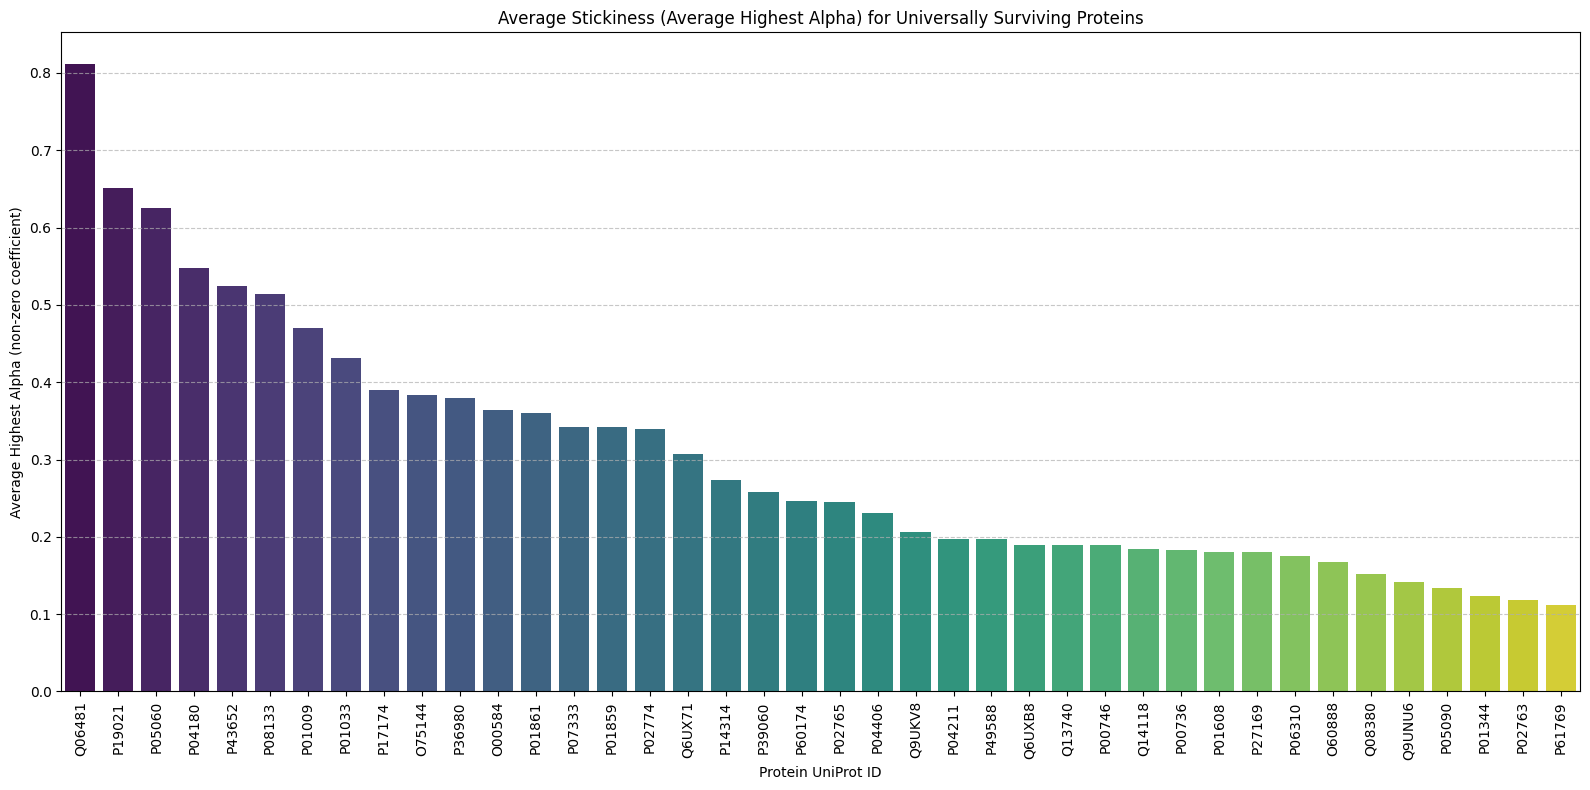

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Dictionary to store the sum of highest alphas and their counts for each universally surviving protein
protein_avg_stickiness = {prot: {'sum_alpha': 0.0, 'count': 0} for prot in universally_surviving_proteins}

# Calculate the sum of highest alphas for each universally surviving protein across all UPDRS scores
for updrs_col in updrs_columns:
    for protein, max_alpha in protein_stickiness.get(updrs_col, []):
        if protein in universally_surviving_proteins:
            protein_avg_stickiness[protein]['sum_alpha'] += max_alpha
            protein_avg_stickiness[protein]['count'] += 1

# Calculate the average highest alpha
final_avg_stickiness = {}
for protein, data in protein_avg_stickiness.items():
    if data['count'] > 0:
        final_avg_stickiness[protein] = data['sum_alpha'] / data['count']

# Sort the proteins by their average stickiness for better visualization
sorted_final_avg_stickiness = sorted(final_avg_stickiness.items(), key=lambda item: item[1], reverse=True)

# Prepare data for plotting
plot_proteins = [item[0] for item in sorted_final_avg_stickiness]
plot_stickiness_values = [item[1] for item in sorted_final_avg_stickiness]

stickiness_chart_df = pd.DataFrame({
    'Protein': plot_proteins,
    'Average Stickiness (Average Highest Alpha)': plot_stickiness_values
})

# Create the bar chart
fig = plt.figure(figsize=(16, 8)) # Adjusted figure size for more proteins
sns.barplot(x='Protein', y='Average Stickiness (Average Highest Alpha)', data=stickiness_chart_df, hue='Protein', palette='viridis', legend=False)
plt.title('Average Stickiness (Average Highest Alpha) for Universally Surviving Proteins')
plt.xlabel('Protein UniProt ID')
plt.ylabel('Average Highest Alpha (non-zero coefficient)')
plt.xticks(rotation=90) # Rotate x-axis labels for readability
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
# @title step_artifacts
num_fig = "2" # @param {type:"string"}
step = 'DataVisualization'  # @param ["DataLoading", "DataExploration", "DataCleaning", "DataWrangling", "DataVisualization", "DataSplitting", "ModelDevelopment", "ModelOptimization", "ModelEvaluation", "Summary"] {type:"string"}
# upload_plt_to_gcs(num_fig, step, fig)